# Data science track: explore, model and score

You pull modelling data from the lake with Athena, train a credit-default model locally, store the artefact in S3 and score a customer from features held in DynamoDB.

**Note:** the emulator runs no training compute, so modelling happens in this notebook with scikit-learn. The AWS services provide the data and storage around it.

In [1]:
import sys, json, time, datetime as dt
sys.path.insert(0, "../..")          # repository root: emu.py, lab_common.py
import pandas as pd
import matplotlib.pyplot as plt
import emu
from lab_common import *

df = ensure_lake()                   # buckets, loan book in S3, Glue table (safe to re-run)
print("Connected to", emu.settings()["endpoint_url"], "-", len(df), "loans in the lake")

Connected to https://127.0.0.1:9297 - 2000 loans in the lake


## 1. Pull the modelling data with Athena

In [2]:
data = run_sql("SELECT * FROM loans")
print(data.shape, "- default rate", f"{data.defaulted.mean():.1%}")
data[FEATURES + ["defaulted"]].describe().T[["mean", "std", "min", "max"]].round(2)

(2000, 11) - default rate 24.0%


,mean,std,min,max
credit_score,689.48,70.37,443.00,900.00
annual_income,65866.05,33885.82,11800.00,393000.00
loan_amount,215217.50,160438.23,16000.00,1101000.00
dti,0.38,0.14,0.05,0.92
tenure_months,45.08,23.34,12.00,84.00
days_past_due,25.78,33.63,0.00,90.00
defaulted,0.24,0.43,0.00,1.00


## 2. Explore: which features separate defaulters?

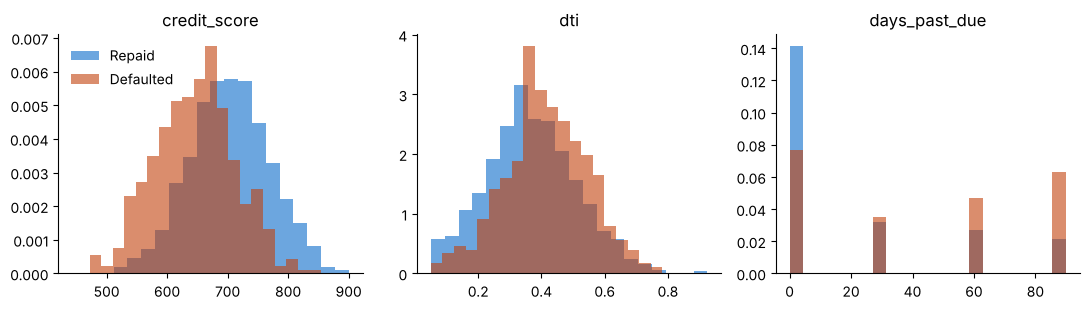

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axes, ["credit_score", "dti", "days_past_due"]):
    for flag, colour, name in [(0, "#0b6bcb", "Repaid"), (1, "#c2410c", "Defaulted")]:
        ax.hist(data.loc[data.defaulted == flag, col], bins=20, alpha=0.6, density=True, color=colour, label=name)
    ax.set_title(col); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

## 3. Train two models and compare on a hold-out set

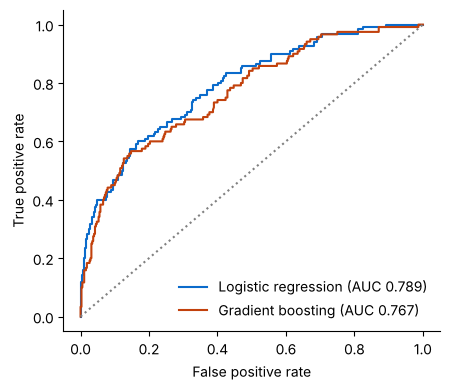

In [4]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

logit, auc_logit, X_test, y_test = train_default_model(data)
X_train, _, y_train, _ = train_test_split(data[FEATURES], data.defaulted, test_size=0.25, random_state=7, stratify=data.defaulted)
gbm = GradientBoostingClassifier(random_state=7).fit(X_train, y_train)
auc_gbm = roc_auc_score(y_test, gbm.predict_proba(X_test)[:, 1])

fig, ax = plt.subplots(figsize=(4.6, 4))
for m, name, colour in [(logit, f"Logistic regression (AUC {auc_logit:.3f})", "#0b6bcb"), (gbm, f"Gradient boosting (AUC {auc_gbm:.3f})", "#c2410c")]:
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1]); ax.plot(fpr, tpr, color=colour, label=name)
ax.plot([0, 1], [0, 1], color="grey", linestyle=":"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(frameon=False, loc="lower right"); ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 4. Store the chosen model in S3

The simpler logistic model is kept: it is easier to explain to a credit committee. The artefact uses the `model.tar.gz` layout SageMaker expects.

In [5]:
import io, pickle, tarfile
buf = io.BytesIO()
with tarfile.open(fileobj=buf, mode="w:gz") as tar:
    blob = pickle.dumps(logit); info = tarfile.TarInfo("model.pkl"); info.size = len(blob)
    tar.addfile(info, io.BytesIO(blob))
s3 = emu.client("s3")
s3.put_object(Bucket=LAKE, Key="models/default-model/model.tar.gz", Body=buf.getvalue(),
              Metadata={"auc": f"{auc_logit:.4f}", "features": ",".join(FEATURES)})
head = s3.head_object(Bucket=LAKE, Key="models/default-model/model.tar.gz")
print("Stored", head["ContentLength"], "bytes with metadata", head["Metadata"])

Stored 1067 bytes with metadata {'auc': '0.7894', 'features': 'credit_score,annual_income,loan_amount,dti,tenure_months,days_past_due'}


## 5. Online scoring from a DynamoDB feature table

Load features into DynamoDB, then score one loan by key, as a real-time decision service would.

In [6]:
ddb = emu.client("dynamodb")
TABLE = "loan_features"
if TABLE not in ddb.list_tables()["TableNames"]:
    ddb.create_table(TableName=TABLE, BillingMode="PAY_PER_REQUEST",
                     AttributeDefinitions=[{"AttributeName": "loan_id", "AttributeType": "S"}],
                     KeySchema=[{"AttributeName": "loan_id", "KeyType": "HASH"}])
    ddb.get_waiter("table_exists").wait(TableName=TABLE, WaiterConfig={"Delay": 1, "MaxAttempts": 20})
sample = data.head(100)
for start in range(0, len(sample), 25):  # BatchWriteItem takes 25 items at most
    ddb.batch_write_item(RequestItems={TABLE: [{"PutRequest": {"Item": {
        "loan_id": {"S": r.loan_id}, **{f: {"N": str(getattr(r, f))} for f in FEATURES}}}}
        for r in sample.iloc[start:start + 25].itertuples()]})

def score(loan_id):
    item = ddb.get_item(TableName=TABLE, Key={"loan_id": {"S": loan_id}})["Item"]
    row = pd.DataFrame([{f: float(item[f]["N"]) for f in FEATURES}])
    return float(logit.predict_proba(row)[0, 1])

pd.DataFrame([{"loan_id": i, "probability_of_default": round(score(i), 3)} for i in sample.loan_id[:5]])

,loan_id,probability_of_default
0,LN100000,0.332
1,LN100001,0.866
2,LN100002,0.086
3,LN100003,0.749
4,LN100004,0.296


## Exercises

1. Add an engineered feature (for example loan amount divided by income) and see whether AUC improves.
2. Choose a probability cut-off that keeps the approval rate at 80% and report the default rate among approved loans.
3. Write the scores back to DynamoDB as a new attribute with `update_item`.